## 7.1 시계열 문제

시계열 분석 : 시간에 따라 변하는 데이터를 사용하여 추이를 분석하는 것 

시계열 형태 
1. 불규칙 변동
2. 추세 변동
3. 순환 변동
4. 계절 변동 

## 7.2 AR, MA, ARMA, ARIMA 

#### 7.2.1 AR 모델 
자기 회귀 모델 : 이전 관측 값이 이ㅜㅎ 관측 값에 영향을 준다는 아이디어에 대한 모형

#### 7.2.2 MA 모델 
이동 평균 모델 : 트렌드가 변화하는 상황에 적합한 회귀 모델 

#### 7.2.3 ARMA 모델 
자기 회귀 이동 평균 : AR, MA 섞은 모델

#### 7.2.4 ARIMA 모델 
자기 회귀 누적 이동 평균 모델은 자기 회귀와 이동 평균을 둘 다 고려하는 모형 . 

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -199.651
Date:                Fri, 13 Nov 2026   AIC                            411.302
Time:                        16:10:29   BIC                            420.634
Sample:                    01-01-1991   HQIC                           414.523
                         - 12-01-1993                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8788      0.227     -3.876      0.000      -1.323      -0.434
ar.L2         -0.2787      0.232     -1.203      0.229      -0.733       0.176
ar.L3         -0.0076      0.270     -0.028      0.9

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


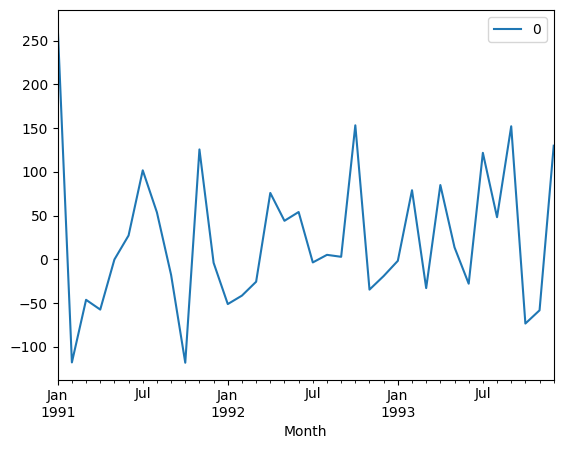

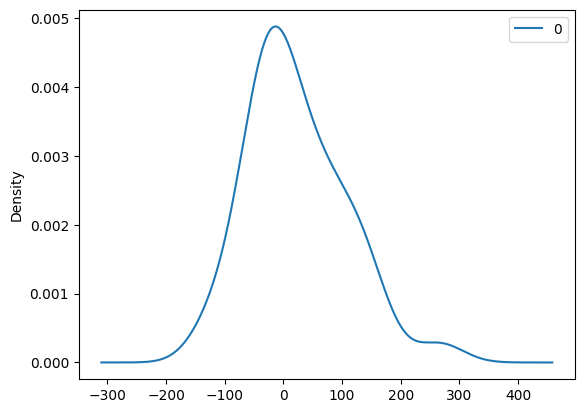

                0
count   36.000000
mean    22.459086
std     82.505331
min   -118.213281
25%    -33.308343
50%      1.361178
75%     76.704967
max    266.000000


In [13]:
from pandas import read_csv
from datetime import datetime
from pandas import DataFrame
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot


def parser(x):
    return datetime.strptime('199'+x, '%Y-%m')


series = read_csv('/Users/seomichelle/26-2 ESAA:Python/dataset/sales.csv', header=0, index_col=0)
series.index = series.index.map(parser)
series = series.squeeze("columns")

model = ARIMA(series, order=(5,1,0))
model_fit = model.fit()
print(model_fit.summary())
residuals = DataFrame(model_fit.resid)
residuals.plot()
pyplot.show()
residuals.plot(kind='kde')
pyplot.show()
print(residuals.describe())

predicted=352.855343, expected=346.300000
predicted=277.398036, expected=329.700000
predicted=368.753734, expected=445.400000
predicted=331.773635, expected=325.900000
predicted=372.070407, expected=449.300000
predicted=360.020872, expected=411.300000
predicted=454.526230, expected=417.400000
predicted=388.690695, expected=545.500000
predicted=437.632447, expected=477.600000
predicted=516.437624, expected=687.000000
predicted=520.916191, expected=435.300000
predicted=675.594647, expected=587.300000
predicted=505.201016, expected=676.900000
Test MSE: 9118.818


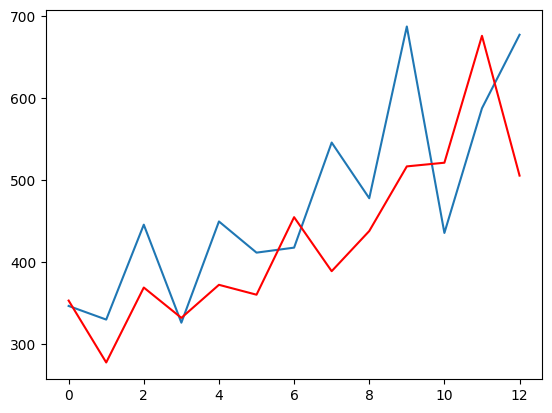

In [14]:
import numpy as np
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error


def parser(x):
    return datetime.strptime('199'+x, '%Y-%m')


series = read_csv('/Users/seomichelle/26-2 ESAA:Python/dataset/sales.csv', header=0, index_col=0)
series.index = series.index.map(parser)

X = series.values.flatten()
X = np.nan_to_num(X)
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()

for t in range(len(test)):
    model = ARIMA(history, order=(5,1,0))
    model_fit = model.fit()
    output = model_fit.forecast()
    yhat = output[0]
    predictions.append(yhat)
    obs = test[t]
    history.append(obs)
    print('predicted=%f, expected=%f' % (yhat, obs))

error = mean_squared_error(test, predictions)
print('Test MSE: %.3f' % error)
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()

### 7.3 순환 신경망 (RNN)

시간적으로 연속성 있는 데이터를 처리하려고 고안된 인공 신경망이다. 

RNN의 입력과 출력에 따라 유형이 다양하다
1. 일대일 : 순환이 없기 때문에 RNN이라고 말하기 어렵다
2. 일대다 : 입력이 하나이고, 출력이 하나인 구조로, 문장을 입력해서 긍정/부정을 출력하는 감성 분석기에서 사용
3. 다대일 : 입력이 다수이고 출력이 하나인 구조